Temperatura ideal para tomarse el tinto: 63.9 °C
Error promedio parabola: 0.25 °C
Error promedio exponencial: 0.15 °C


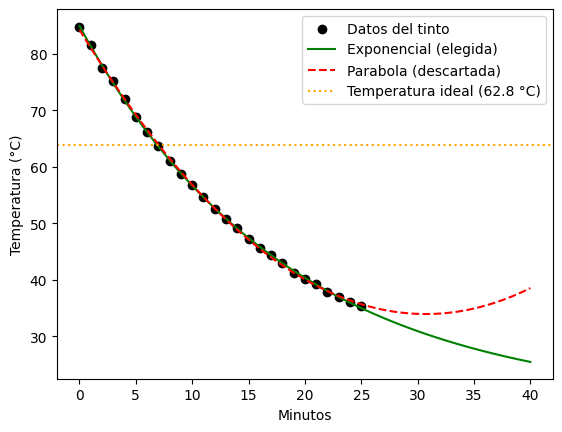

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Abrimos las dos tablas
datos_cafe = pd.read_csv("cotter_dataset.csv")
datos_tinto = pd.read_csv("mediciones_tinto.csv")

# 2. Buscamos a que temperatura le gusta el cafe a la gente (Temp == 3 es temperatura justa)
temperatura_justa = datos_cafe[datos_cafe["Temp"] == 3]
temp_ideal = temperatura_justa["90Sec Temp"].mean()
print("Temperatura ideal para tomarse el tinto:", round(temp_ideal, 1), "°C")

# 3. Sacamos los minutos y grados de la primera taza (corrida 1)
taza1 = datos_tinto[datos_tinto["corrida"] == 1]
minutos = taza1["minuto"]
grados = taza1["temperatura_C"]

# 4. Probamos el Modelo 1: Parabola (grado 2)
a, b, c = np.polyfit(minutos, grados, 2)
prediccion_parabola = a * minutos**2 + b * minutos + c
error_parabola = np.mean(np.abs(grados - prediccion_parabola))

# 5. Probamos el Modelo 2: Exponencial (Ley de Newton, ambiente = 18 °C)
def formula_newton(t, T0, k):
    return 18 + (T0 - 18) * np.exp(-k * t)

valores, _ = curve_fit(formula_newton, minutos, grados, p0=[85, 0.05])
T0, k = valores
prediccion_newton = formula_newton(minutos, T0, k)
error_newton = np.mean(np.abs(grados - prediccion_newton))

print("Error promedio parabola:", round(error_parabola, 2), "°C")
print("Error promedio exponencial:", round(error_newton, 2), "°C")

# 6. Dibujamos la grafica hasta el minuto 40 para comparar
t_largo = np.linspace(0, 40, 100)
plt.scatter(minutos, grados, color="black", label="Datos del tinto")
plt.plot(t_largo, formula_newton(t_largo, T0, k), color="green", label="Exponencial (elegida)")
plt.plot(t_largo, a * t_largo**2 + b * t_largo + c, color="red", linestyle="--", label="Parabola (descartada)")
plt.axhline(temp_ideal, color="orange", linestyle=":", label="Temperatura ideal (62.8 °C)")
plt.xlabel("Minutos")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.show()
